# 1. Среда и воспроизводимость

Используем Google Colab с GPU T4. Фиксируем `seed = 42` для Python, NumPy, PyTorch и CUDA, чтобы воспроизводить разбиение и проверку модели в одной и той же среде.


In [1]:
!pip install -q albumentations imagehash datasets huggingface_hub opencv-python-headless

import os
import random
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen
from zipfile import BadZipFile, ZipFile
import json
import re

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import albumentations as A
import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, get_worker_info
from tqdm.auto import tqdm

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
cv2.setNumThreads(1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_name = torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU"
print(f"Устройство {device} ({device_name}), seed = {seed}.")

Устройство cuda (Tesla T4), seed = 42.


# 2. Загрузка дерматоскопических снимков и масок

Используем только обучающие архивы ISIC 2016 Task 1 по лицензии CC0. Напрямую скачиваем 900 пар дерматоскопических снимков и бинарных масок без токенов и авторизации. Сопоставляем файлы по идентификатору ISIC. Сохраняем JPEG в `data/images` и PNG с пикселями 0 и 1 в `data/masks`. После удаления одной точной копии и восьми близких копий по pHash остаётся 891 пара. [Официальная страница ISIC 2016 Task 1](https://challenge.isic-archive.com/landing/2016/37/)


Загрузка ISBI2016_ISIC_Part1_Training_GroundTruth.zip:   0%|          | 0.00/6.00M [00:00<?, ?Б/s]

Загрузка ISBI2016_ISIC_Part1_Training_Data.zip:   0%|          | 0.00/632M [00:00<?, ?Б/s]

Сохранение пар:   0%|          | 0/900 [00:00<?, ?it/s]

Загружено 900 пар из ISIC 2016 Task 1.


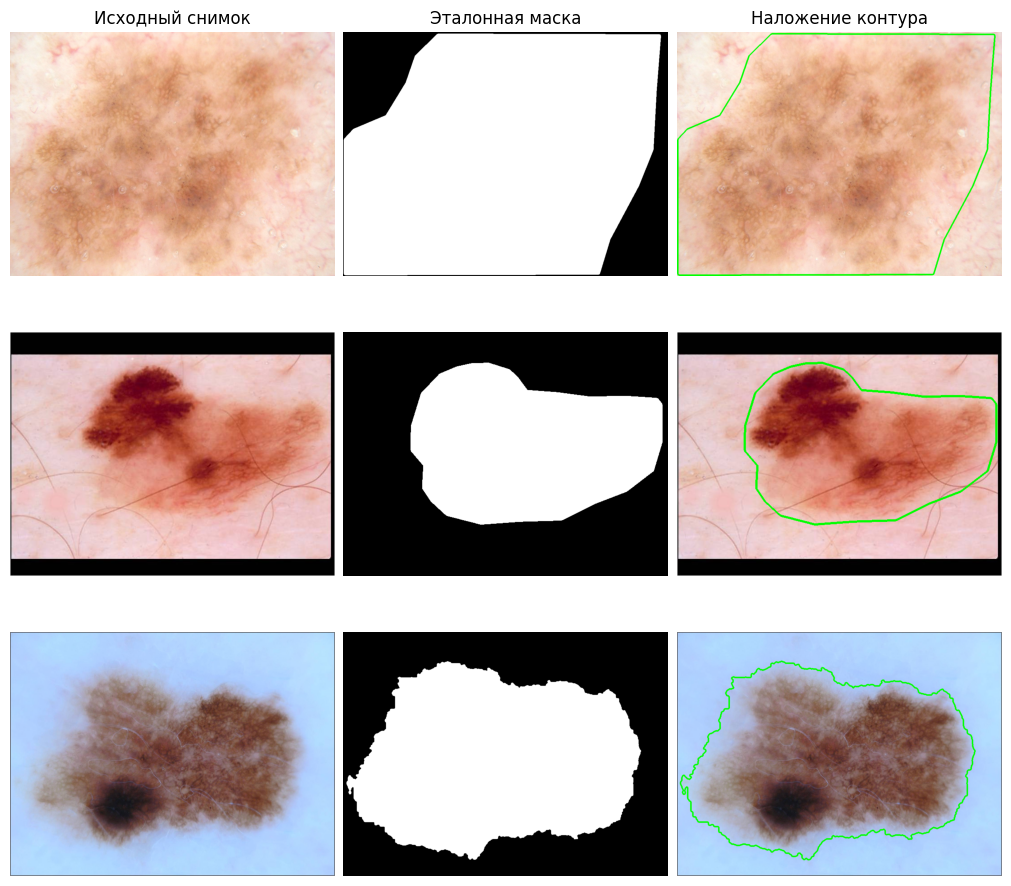

In [2]:
dataset_name = "ISIC 2016 Task 1"
expected_count = 900
archive_base = "https://isic-archive.s3.amazonaws.com/challenges/2016"
image_url = f"{archive_base}/ISBI2016_ISIC_Part1_Training_Data.zip"
mask_url = f"{archive_base}/ISBI2016_ISIC_Part1_Training_GroundTruth.zip"


def download_archive(url, archive_dir):
    destination = archive_dir / url.rsplit("/", 1)[-1]
    if destination.is_file():
        try:
            with ZipFile(destination):
                return destination
        except BadZipFile:
            destination.unlink()

    partial = destination.with_suffix(".zip.part")
    try:
        with urlopen(url, timeout=45) as response, partial.open("wb") as output:
            total = response.headers.get("Content-Length")
            with tqdm(
                total=int(total) if total else None,
                desc=f"Загрузка {destination.name}",
                unit="Б",
                unit_scale=True,
                leave=False,
            ) as progress:
                while chunk := response.read(1024 * 1024):
                    output.write(chunk)
                    progress.update(len(chunk))
        with ZipFile(partial):
            pass
        partial.replace(destination)
    finally:
        partial.unlink(missing_ok=True)
    return destination


def index_archive(archive, filename_pattern):
    members = {}
    for member in archive.infolist():
        match = re.fullmatch(filename_pattern, Path(member.filename).name, re.IGNORECASE)
        if member.is_dir() or not match:
            continue
        image_id = match.group(1).upper()
        if image_id in members:
            raise ValueError(f"Обнаружен повторяющийся идентификатор {image_id} внутри архива.")
        members[image_id] = member
    return members


def prepare_pairs(root):
    archive_dir = root / ".archives"
    archive_dir.mkdir(exist_ok=True)
    mask_archive = download_archive(mask_url, archive_dir)
    image_archive = download_archive(image_url, archive_dir)

    with (
        ZipFile(image_archive) as images,
        ZipFile(mask_archive) as masks,
        TemporaryDirectory(dir=root) as staging_dir,
    ):
        image_members = index_archive(images, r"(ISIC_\d+)\.jpe?g")
        mask_members = index_archive(masks, r"(ISIC_\d+)(?:_segmentation)?\.png")
        if len(image_members) != expected_count or image_members.keys() != mask_members.keys():
            raise ValueError(
                f"Ожидалось {expected_count} совпадающих пар. Найдено "
                f"{len(image_members)} снимков и {len(mask_members)} масок."
            )

        image_ids = sorted(image_members)
        staging = Path(staging_dir)
        for image_id in tqdm(image_ids, desc="Сохранение пар", leave=False):
            jpeg_bytes = images.read(image_members[image_id])
            with (
                Image.open(BytesIO(jpeg_bytes)) as image,
                Image.open(BytesIO(masks.read(mask_members[image_id]))) as mask,
            ):
                if image.size != mask.size:
                    raise ValueError(f"Размеры снимка и маски {image_id} различаются.")
                image_path = staging / f"{image_id}.jpg"
                if image.mode == "RGB":
                    image_path.write_bytes(jpeg_bytes)
                else:
                    image.convert("RGB").save(image_path, quality=95)
                binary_mask = (np.asarray(mask.convert("L")) > 0).astype(np.uint8)
                Image.fromarray(binary_mask).save(staging / f"{image_id}.png")

        for image_id in image_ids:
            (staging / f"{image_id}.jpg").replace(root / "images" / f"{image_id}.jpg")
            (staging / f"{image_id}.png").replace(root / "masks" / f"{image_id}.png")
        manifest = staging / "dataset.json"
        manifest.write_text(
            json.dumps({"source": dataset_name, "image_ids": image_ids}), encoding="utf-8"
        )
        manifest.replace(root / "dataset.json")

    return image_ids


def load_skin_lesions(data_dir="data"):
    root = Path(data_dir)
    for directory in (root / "images", root / "masks"):
        directory.mkdir(parents=True, exist_ok=True)

    def pair_paths(image_ids):
        return [
            (root / "images" / f"{image_id}.jpg", root / "masks" / f"{image_id}.png")
            for image_id in image_ids
        ]

    manifest_path = root / "dataset.json"
    if manifest_path.is_file():
        try:
            manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
            if manifest["source"] == dataset_name:
                pairs = pair_paths(manifest["image_ids"])
                if len(pairs) == expected_count and all(
                    image.is_file() and mask.is_file() for image, mask in pairs
                ):
                    return pairs
        except (OSError, KeyError, TypeError, ValueError):
            print("Список сохранённых пар прочитать не удалось. Данные подготавливаются заново.")

    return pair_paths(prepare_pairs(root))


pairs = load_skin_lesions()
print(f"Загружено {len(pairs)} пар из {dataset_name}.")

figure, axes = plt.subplots(3, 3, figsize=(10, 9), layout="constrained")
examples = random.Random(seed).sample(pairs, k=3)
for row, (image_path, mask_path) in enumerate(examples):
    with Image.open(image_path) as image_file, Image.open(mask_path) as mask_file:
        image = np.array(image_file.convert("RGB"))
        mask = np.array(mask_file, dtype=np.uint8)

    contours, _ = cv2.findContours(mask, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    overlay = image.copy()
    cv2.drawContours(overlay, contours, -1, (0, 255, 0), max(2, round(min(mask.shape) / 200)))
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].imshow(overlay)
    for axis in axes[row]:
        axis.axis("off")

for axis, title in zip(axes[0], ("Исходный снимок", "Эталонная маска", "Наложение контура")):
    axis.set_title(title)
os.makedirs("assets", exist_ok=True)
plt.savefig("assets/dataset_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Дисбаланс пикселей, дубликаты и разбиение

Измеряем долю очага на исходных масках до ресайза и аугментаций. Находим точные копии по SHA-256 декодированных RGB-пикселей и объединяем оставшиеся снимки в группы по pHash с расстоянием Хэмминга до 4 включительно. Сохраняем по одному снимку из каждой группы, включая группы с транзитивными совпадениями. После очистки делим пары на train, val и test в пропорции 80/10/10. Проверка по pHash снижает риск утечки похожих кадров. Принадлежность снимков одному пациенту отдельно не проверяется.


In [3]:
def find_unique_indices(pairs, max_distance=4):
    unique_pixels = set()
    candidates = []
    hashes = []
    for index, (image_path, _) in enumerate(tqdm(pairs, desc="Расчёт pHash", leave=False)):
        with Image.open(image_path) as photo:
            rgb = photo.convert("RGB")
            pixel_key = (rgb.size, sha256(rgb.tobytes()).digest())
            perceptual_hash = int(str(imagehash.phash(rgb)), 16)
        if pixel_key in unique_pixels:
            continue
        unique_pixels.add(pixel_key)
        candidates.append(index)
        hashes.append(perceptual_hash)

    parents = list(range(len(candidates)))

    def find_root(index):
        while parents[index] != index:
            parents[index] = parents[parents[index]]
            index = parents[index]
        return index

    for right, right_hash in enumerate(hashes):
        for left in range(right):
            if (hashes[left] ^ right_hash).bit_count() <= max_distance:
                first, second = sorted((find_root(left), find_root(right)))
                parents[second] = first

    keep = [original for index, original in enumerate(candidates) if index == find_root(index)]
    return keep, len(pairs) - len(candidates), len(candidates) - len(keep)


lesion_fractions = []
for _, mask_path in pairs:
    with Image.open(mask_path) as mask:
        lesion_fractions.append(np.asarray(mask).mean())
lesion_fractions = np.asarray(lesion_fractions)

print(
    f"Доля очага по снимкам. Средняя — {lesion_fractions.mean():.2%}, "
    f"медианная — {np.median(lesion_fractions):.2%}, "
    f"минимальная — {lesion_fractions.min():.2%}, максимальная — {lesion_fractions.max():.2%}."
)
print(f"Средняя доля фона — {1 - lesion_fractions.mean():.2%}.")

keep_indices, exact_duplicates, near_duplicates = find_unique_indices(pairs)
clean_pairs = [pairs[index] for index in keep_indices]
print(
    f"Удалено {exact_duplicates + near_duplicates} повторов. "
    f"Точных — {exact_duplicates}, близких по pHash — {near_duplicates}. "
    f"Сохранено {len(clean_pairs)} пар."
)

order = np.random.default_rng(seed).permutation(len(clean_pairs))
holdout_size = round(0.10 * len(order))
val_end = 2 * holdout_size
test_pairs = [clean_pairs[index] for index in order[:holdout_size]]
val_pairs = [clean_pairs[index] for index in order[holdout_size:val_end]]
train_pairs = [clean_pairs[index] for index in order[val_end:]]

for name, split in (("train", train_pairs), ("val", val_pairs), ("test", test_pairs)):
    print(f"{name} — {len(split)} пар ({len(split) / len(clean_pairs):.1%}).")

Доля очага по снимкам. Средняя — 27.09%, медианная — 21.35%, минимальная — 1.16%, максимальная — 99.54%.
Средняя доля фона — 72.91%.


Расчёт pHash:   0%|          | 0/900 [00:00<?, ?it/s]

Удалено 9 повторов. Точных — 1, близких по pHash — 8. Сохранено 891 пар.
train — 713 пар (80.0%).
val — 89 пар (10.0%).
test — 89 пар (10.0%).


# 4. Dataset, ресайз и аугментации

Приводим снимки и маски к 256 × 256. При ресайзе масок и геометрических преобразованиях используем интерполяцию по ближайшему соседу, чтобы сохранить метки 0 и 1. Сдвиги, отражения и повороты применяем к обучающим парам. Яркость и контраст меняем только у обучающих снимков. Нормализацию RGB по ImageNet применяем ко всем выборкам.


In [4]:
image_size = 256
batch_size = 16
num_workers = 2
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

train_transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.ShiftScaleRotate(
            p=0.5,
            interpolation=cv2.INTER_LINEAR,
            mask_interpolation=cv2.INTER_NEAREST,
            border_mode=cv2.BORDER_CONSTANT,
        ),
        A.RandomBrightnessContrast(p=0.3),
        A.Normalize(mean=imagenet_mean, std=imagenet_std),
    ],
    seed=seed,
)
eval_transform = A.Compose([A.Normalize(mean=imagenet_mean, std=imagenet_std)])


class SkinLesionDataset(torch.utils.data.Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        with Image.open(image_path) as image_file, Image.open(mask_path) as mask_file:
            image = np.array(image_file.convert("RGB"))
            mask = np.array(mask_file, dtype=np.uint8)

        size = (image_size, image_size)
        image = cv2.resize(image, size, interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST)
        augmented = self.transform(image=image, mask=mask)
        image_tensor = torch.from_numpy(augmented["image"]).permute(2, 0, 1).contiguous()
        mask_tensor = torch.from_numpy(augmented["mask"]).unsqueeze(0).float()
        return image_tensor, mask_tensor


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)
    cv2.setNumThreads(1)
    get_worker_info().dataset.transform.set_random_seed(worker_seed)


train_dataset = SkinLesionDataset(train_pairs, train_transform)
val_dataset = SkinLesionDataset(val_pairs, eval_transform)
test_dataset = SkinLesionDataset(test_pairs, eval_transform)

loader_settings = dict(
    batch_size=batch_size,
    num_workers=num_workers,
    pin_memory=True,
    worker_init_fn=seed_worker,
)
train_generator = torch.Generator().manual_seed(seed)
train_loader = DataLoader(
    train_dataset, shuffle=True, generator=train_generator, **loader_settings
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_settings)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_settings)

sample_images, sample_masks = next(iter(train_loader))
train_generator.manual_seed(seed)
assert sample_images.shape == (batch_size, 3, image_size, image_size)
assert sample_masks.shape == (batch_size, 1, image_size, image_size)
assert torch.all((sample_masks == 0) | (sample_masks == 1))
print(f"Проверка батча. Снимки {tuple(sample_images.shape)}, маски {tuple(sample_masks.shape)}.")

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Проверка батча. Снимки (16, 3, 256, 256), маски (16, 1, 256, 256).


# 5. U-Net и комбинированный лосс

Собрали четыре уровня энкодера с 32, 64, 128 и 256 каналами и промежуточный блок на 512 каналов. На каждом шаге декодера удваиваем разрешение и конкатенируем результат с признаками энкодера. Свёртка 1 × 1 выдаёт один логит на пиксель.

$$
\mathcal{L} = 1 - \text{Dice} + \lambda \mathcal{L}_{\text{focal}}
$$

Считаем Dice по вероятностям отдельно для каждого снимка и усредняем. Focal считаем по логитам через `binary_cross_entropy_with_logits` с весом `alpha = 0.25` для очага, `1 - alpha` для фона и `gamma = 2.0`. Используем `lambda_focal = 1.0` и `smooth = 1e-6`. На CUDA включаем AMP для прямого прохода модели и считаем лосс в FP32. На CPU проверяем тот же батч частями, чтобы ограничить расход памяти.

Модель выделяет область интереса для специалиста, но маска сама по себе не является диагнозом.


In [5]:
def double_conv(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        channels = (32, 64, 128, 256)
        self.encoder = nn.ModuleList(
            double_conv(in_channels, out_channels)
            for in_channels, out_channels in zip((3, *channels), channels)
        )
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.bottleneck = double_conv(256, 512)
        self.upsample = nn.ModuleList(
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
            for in_channels, out_channels in zip((512, 256, 128, 64), reversed(channels))
        )
        self.decoder = nn.ModuleList(
            double_conv(2 * channel, channel) for channel in reversed(channels)
        )
        self.head = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, images):
        features = images
        skips = []
        for down in self.encoder:
            features = down(features)
            skips.append(features)
            features = self.pool(features)
        features = self.bottleneck(features)
        for up, decode, skip in zip(self.upsample, self.decoder, reversed(skips)):
            features = decode(torch.cat((up(features), skip), dim=1))
        return self.head(features)


class DiceFocalLoss(nn.Module):
    def __init__(self, lambda_focal=1.0, alpha=0.25, gamma=2.0, smooth=1e-6):
        super().__init__()
        self.lambda_focal = lambda_focal
        self.alpha = alpha
        self.gamma = gamma
        self.smooth = smooth

    def forward(self, logits, targets):
        logits, targets = logits.float(), targets.float()
        probabilities = logits.sigmoid().flatten(1)
        flat_targets = targets.flatten(1)
        intersection = (probabilities * flat_targets).sum(dim=1)
        dice = (2 * intersection + self.smooth) / (
            probabilities.sum(dim=1) + flat_targets.sum(dim=1) + self.smooth
        )

        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        p_t = (-bce).exp()
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        focal = (alpha_t * (1 - p_t).pow(self.gamma) * bce).mean()
        return 1 - dice.mean() + self.lambda_focal * focal


model = UNet().to(device)
criterion = DiceFocalLoss()
use_amp = device.type == "cuda"
micro_batch_size = batch_size if use_amp else 2
check_loss = torch.zeros((), device=device)

# Фиксируем статистики BatchNorm на время проверочного прохода.
model.eval()
try:
    for images, masks in zip(sample_images.split(micro_batch_size), sample_masks.split(micro_batch_size)):
        images = images.to(device, non_blocking=use_amp)
        masks = masks.to(device, non_blocking=use_amp)
        with torch.amp.autocast(device_type=device.type, enabled=use_amp):
            logits = model(images)
        assert logits.shape == masks.shape, (logits.shape, masks.shape)
        loss = criterion(logits, masks) * (len(images) / len(sample_images))
        loss.backward()
        check_loss += loss.detach()

    gradients = [parameter.grad for parameter in model.parameters() if parameter.requires_grad]
    assert torch.isfinite(check_loss), "Проверочный лосс вышел за пределы конечных чисел."
    assert all(gradient is not None for gradient in gradients), "У части параметров нет градиентов."
    gradient_norms = torch.stack([gradient.norm() for gradient in gradients])
    assert torch.isfinite(gradient_norms).all(), "Обнаружены NaN или Inf в градиентах."
    assert gradient_norms.max() > 0, "Все градиенты нулевые."
    print(f"Размер логитов {tuple(sample_masks.shape)}. Dice + Focal Loss = {check_loss.item():.6f}.")
    print("Обратный проход выполнен. У всех обучаемых параметров есть конечные градиенты.")
finally:
    model.zero_grad(set_to_none=True)
    model.train()

Размер логитов (16, 1, 256, 256). Dice + Focal Loss = 0.760275.
Обратный проход выполнен. У всех обучаемых параметров есть конечные градиенты.


# 6. Обучение U-Net на GPU T4

Обучаем модель 25 эпох. Используем AdamW с начальным шагом `1e-3` и `weight_decay = 1e-4`. CosineAnnealingLR обновляет шаг после каждой эпохи. На CUDA используем автоматическую смешанную точность и GradScaler. Для расчёта лосса переводим логиты в FP32.

На каждой эпохе усредняем лосс и Dice по снимкам. Для выбора весов считаем Dice на валидации при пороге 0,50. Сохраняем веса с максимальным валидационным Dice в `best_unet.pth`. При равном Dice сохраняем веса более ранней эпохи.


/tmp/ipykernel_528/712114586.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


Эпоха 01/25. train_loss = 0.6255, val_loss = 0.7850, val_dice = 0.6323
Эпоха 02/25. train_loss = 0.5023, val_loss = 0.4945, val_dice = 0.7443
Эпоха 03/25. train_loss = 0.4392, val_loss = 0.4345, val_dice = 0.7813
Эпоха 04/25. train_loss = 0.3852, val_loss = 0.3759, val_dice = 0.7793
Эпоха 05/25. train_loss = 0.3206, val_loss = 0.2873, val_dice = 0.8296
Эпоха 06/25. train_loss = 0.3103, val_loss = 0.2803, val_dice = 0.8245
Эпоха 07/25. train_loss = 0.2971, val_loss = 0.2801, val_dice = 0.8281
Эпоха 08/25. train_loss = 0.2790, val_loss = 0.2602, val_dice = 0.8412
Эпоха 09/25. train_loss = 0.2576, val_loss = 0.2474, val_dice = 0.8374
Эпоха 10/25. train_loss = 0.2539, val_loss = 0.2468, val_dice = 0.8471
Эпоха 11/25. train_loss = 0.2507, val_loss = 0.2305, val_dice = 0.8526
Эпоха 12/25. train_loss = 0.2312, val_loss = 0.2201, val_dice = 0.8600
Эпоха 13/25. train_loss = 0.2351, val_loss = 0.2232, val_dice = 0.8590
Эпоха 14/25. train_loss = 0.2317, val_loss = 0.2121, val_dice = 0.8658
Эпоха 

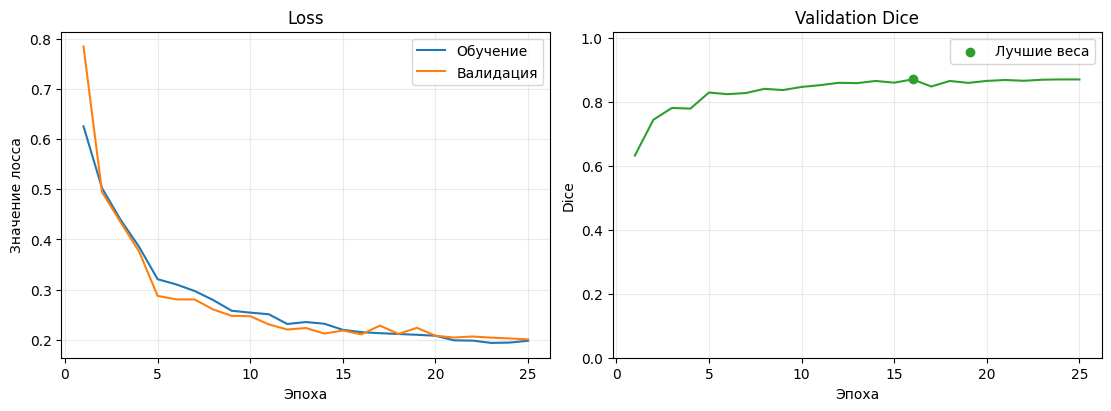

In [6]:
epochs = 25
checkpoint_path = Path("best_unet.pth")

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


def binary_dice(prediction, target):
    intersection = (prediction & target).flatten(1).sum(dim=1)
    total_area = prediction.flatten(1).sum(dim=1) + target.flatten(1).sum(dim=1)
    dice = 2 * intersection / total_area.clamp_min(1)
    return torch.where(total_area == 0, 1.0, dice)


history = {"train_loss": [], "val_loss": [], "val_dice": []}
best_val_dice = float("-inf")
for epoch in range(1, epochs + 1):
    model.train()
    train_loss_sum = torch.zeros((), device=device)
    for images, masks in train_loader:
        images = images.to(device, non_blocking=use_amp)
        masks = masks.to(device, non_blocking=use_amp)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=device.type, enabled=use_amp):
            logits = model(images)
        loss = criterion(logits, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_loss_sum += loss.detach() * len(images)

    model.eval()
    val_loss_sum = torch.zeros((), device=device)
    val_dice_sum = torch.zeros((), device=device)
    with torch.inference_mode():
        for images, masks in val_loader:
            images = images.to(device, non_blocking=use_amp)
            masks = masks.to(device, non_blocking=use_amp)
            with torch.amp.autocast(device_type=device.type, enabled=use_amp):
                logits = model(images)
            val_loss_sum += criterion(logits, masks) * len(images)
            val_dice_sum += binary_dice(logits >= 0, masks.bool()).sum()

    train_loss = train_loss_sum.item() / len(train_loader.dataset)
    val_loss = val_loss_sum.item() / len(val_loader.dataset)
    val_dice = val_dice_sum.item() / len(val_loader.dataset)
    if not np.isfinite([train_loss, val_loss, val_dice]).all():
        raise RuntimeError(f"Неконечная метрика на эпохе {epoch}.")
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        best_epoch = epoch
        torch.save(model.state_dict(), checkpoint_path)

    print(
        f"Эпоха {epoch:02d}/{epochs}. train_loss = {train_loss:.4f}, "
        f"val_loss = {val_loss:.4f}, val_dice = {val_dice:.4f}"
    )
    scheduler.step()

print(f"Лучшие веса сохранены с эпохи {best_epoch}. Validation Dice = {best_val_dice:.4f}.")

epoch_numbers = range(1, epochs + 1)
figure, (loss_axis, dice_axis) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
loss_axis.plot(epoch_numbers, history["train_loss"], label="Обучение")
loss_axis.plot(epoch_numbers, history["val_loss"], label="Валидация")
loss_axis.set(title="Loss", xlabel="Эпоха", ylabel="Значение лосса")
loss_axis.legend()
dice_axis.plot(epoch_numbers, history["val_dice"], color="tab:green")
dice_axis.scatter(best_epoch, best_val_dice, color="tab:green", zorder=3, label="Лучшие веса")
dice_axis.set(title="Validation Dice", xlabel="Эпоха", ylabel="Dice", ylim=(0, 1.02))
dice_axis.legend()
for axis in (loss_axis, dice_axis):
    axis.grid(alpha=0.25)

os.makedirs("assets", exist_ok=True)
plt.savefig("assets/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(figure)


# 7. Подбор порога бинаризации на валидации

Загружаем лучшие веса и за один проход по валидации оцениваем пороги от 0,30 до 0,70 с шагом 0,05. Выбираем порог с максимальным средним Dice по снимкам. При равенстве берём порог, ближайший к 0,50, а при равном расстоянии — меньший.


Оптимальный порог 0.55. Validation Dice = 0.8710.


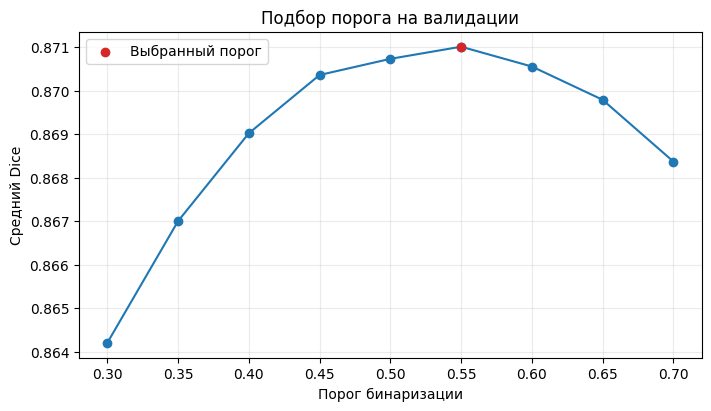

In [7]:
model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
model.eval()


@torch.inference_mode()
def predict_probabilities(loader):
    for images, masks in loader:
        images = images.to(device, non_blocking=use_amp)
        with torch.amp.autocast(device_type=device.type, enabled=use_amp):
            logits = model(images)
        yield logits.float().sigmoid().cpu(), masks.bool()


threshold_percentages = tuple(range(30, 71, 5))
threshold_dice_sums = np.zeros(len(threshold_percentages), dtype=np.float64)
for probabilities, targets in predict_probabilities(val_loader):
    for index, threshold in enumerate(threshold_percentages):
        dice = binary_dice(probabilities >= threshold / 100, targets)
        threshold_dice_sums[index] += dice.sum(dtype=torch.float64).item()

threshold_dice = threshold_dice_sums / len(val_loader.dataset)
best_index = max(
    range(len(threshold_percentages)),
    key=lambda index: (threshold_dice[index], -abs(threshold_percentages[index] - 50), -index),
)
best_threshold = threshold_percentages[best_index] / 100
print(f"Оптимальный порог {best_threshold:.2f}. Validation Dice = {threshold_dice[best_index]:.4f}.")

thresholds = np.asarray(threshold_percentages) / 100
figure, axis = plt.subplots(figsize=(7, 4), layout="constrained")
axis.plot(thresholds, threshold_dice, marker="o")
axis.scatter(best_threshold, threshold_dice[best_index], color="tab:red", zorder=3, label="Выбранный порог")
axis.set(title="Подбор порога на валидации", xlabel="Порог бинаризации", ylabel="Средний Dice", xticks=thresholds)
axis.legend()
axis.grid(alpha=0.25)
os.makedirs("assets", exist_ok=True)
plt.savefig("assets/threshold_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(figure)


# 8. Оценка на тестовой выборке по размеру очага

Оцениваем отложенный тест с зафиксированными весами и порогом. Считаем Dice и IoU (Jaccard) по маскам 256 × 256. Считаем Boundary IoU по внутренним полосам шириной 3 пикселя и определяем ошибку границы как `1 − Boundary IoU`. Полосу получаем как разность между маской и её эрозией квадратным ядром 3 × 3 за три итерации. За пределами кадра считаем пиксели фоном. При двух пустых масках Dice и IoU равны 1, в том числе для полос.

Размер очага определяем по доле пикселей исходной эталонной маски до ресайза. Мелкие очаги занимают менее 5% кадра, средние — от 5% до 20% включительно, крупные — более 20%. В сводке каждый снимок имеет одинаковый вес.


ISIC 2016 Task 1, тестовая выборка из 89 снимков, порог 0.55.
Test Dice = 0.8758
Test IoU (Jaccard) = 0.7957
Boundary IoU = 0.1407
Ошибка границы = 0.8593

Размер очага           N    Dice     IoU Boundary IoU Ошибка границы
Мелкие (<5%)           3  0.7119  0.5790       0.1663         0.8337
Средние (5–20%)       30  0.8920  0.8136       0.1812         0.8188
Крупные (>20%)        56  0.8759  0.7977       0.1176         0.8824


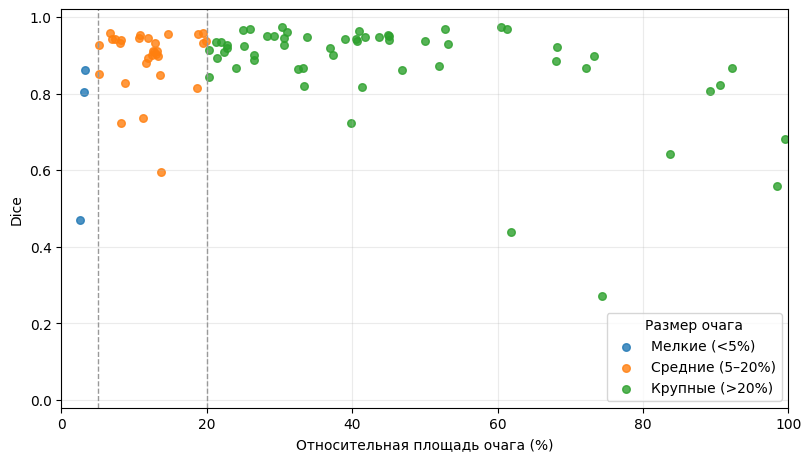

In [8]:
boundary_kernel = np.ones((3, 3), dtype=np.uint8)
size_labels = ("Мелкие (<5%)", "Средние (5–20%)", "Крупные (>20%)")
original_area = {mask_path: fraction for (_, mask_path), fraction in zip(pairs, lesion_fractions)}


def mask_iou(prediction, target):
    union = np.count_nonzero(prediction | target)
    return np.count_nonzero(prediction & target) / union if union else 1.0


def inner_boundary(mask):
    eroded = cv2.erode(
        mask.astype(np.uint8), boundary_kernel,
        iterations=3, borderType=cv2.BORDER_CONSTANT, borderValue=0,
    )
    return mask & (eroded == 0)


test_results = []
for probabilities, targets in predict_probabilities(test_loader):
    predictions = probabilities >= best_threshold
    dice_scores = binary_dice(predictions, targets).tolist()
    for prediction, target, dice in zip(predictions[:, 0].numpy(), targets[:, 0].numpy(), dice_scores):
        image_path, mask_path = test_pairs[len(test_results)]
        area = float(original_area[mask_path])
        size_group = 0 if area < 0.05 else 1 if area <= 0.20 else 2
        boundary_iou = mask_iou(inner_boundary(prediction), inner_boundary(target))
        test_results.append({
            "image_path": image_path,
            "area": area,
            "size_group": size_group,
            "dice": dice,
            "iou": mask_iou(prediction, target),
            "boundary_iou": boundary_iou,
            "boundary_error": 1 - boundary_iou,
            "prediction": prediction,
            "target": target,
        })

metric_keys = ("dice", "iou", "boundary_iou", "boundary_error")
metric_names = ("Test Dice", "Test IoU (Jaccard)", "Boundary IoU", "Ошибка границы")
print(f"{dataset_name}, тестовая выборка из {len(test_results)} снимков, порог {best_threshold:.2f}.")
for key, name in zip(metric_keys, metric_names):
    print(f"{name} = {np.mean([row[key] for row in test_results]):.4f}")

print(f"\n{'Размер очага':<19} {'N':>4} {'Dice':>7} {'IoU':>7} {'Boundary IoU':>12} {'Ошибка границы':>14}")
figure, axis = plt.subplots(figsize=(8, 4.5), layout="constrained")
for group, label in enumerate(size_labels):
    rows = [row for row in test_results if row["size_group"] == group]
    if not rows:
        print(f"{label:<19} {0:>4} {'—':>7} {'—':>7} {'—':>12} {'—':>14}")
        continue
    dice, iou, boundary, error = (np.mean([row[key] for row in rows]) for key in metric_keys)
    print(f"{label:<19} {len(rows):>4} {dice:>7.4f} {iou:>7.4f} {boundary:>12.4f} {error:>14.4f}")
    axis.scatter(
        [100 * row["area"] for row in rows], [row["dice"] for row in rows],
        label=label, alpha=0.8, s=30,
    )

for cutoff in (5, 20):
    axis.axvline(cutoff, color="0.6", linestyle="--", linewidth=1)
axis.set(xlabel="Относительная площадь очага (%)", ylabel="Dice", xlim=(0, 100), ylim=(-0.02, 1.02))
axis.legend(title="Размер очага")
axis.grid(alpha=0.25)
os.makedirs("assets", exist_ok=True)
plt.savefig("assets/size_error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(figure)


# 9. Демо-визуализация и разбор ошибок

Показываем три лучших и три худших тестовых снимка по Dice. При равенстве сортируем по идентификатору снимка. Сначала выбираем худшие случаи, чтобы исключить повторы в сетке. Зелёным обводим исходную разметку, красным — предсказание. Изображения и контуры показаны в координатах маски 256 × 256.

Для худших случаев выводим долю пропущенных пикселей очага и долю фона, ошибочно включённого в маску. В зоне расхождения отмечаем тёмные локальные линии, почти белые участки и низкий контраст пропущенной границы. Эти признаки указывают на возможные причины ошибки, включая волосы, блики и размытие границы.


ISIC_0010495 · Dice 0.272 · очаг 74.3%. Пропущено 84.3% очага. В маску добавлено 0.0% фона.
Возможные факторы ошибки — у пропущенного участка границы низкий контраст.
ISIC_0011109 · Dice 0.440 · очаг 61.8%. Пропущено 67.1% очага. В маску добавлено 27.2% фона.
Возможные факторы ошибки — у пропущенного участка границы низкий контраст.
ISIC_0001191 · Dice 0.469 · очаг 2.6%. Пропущено 0.0% очага. В маску добавлено 6.0% фона.
Возможные факторы ошибки — мелкий очаг, поэтому ошибка занимает значительную часть его площади, в зоне ошибки есть тёмные детали, возможен волосяной покров.


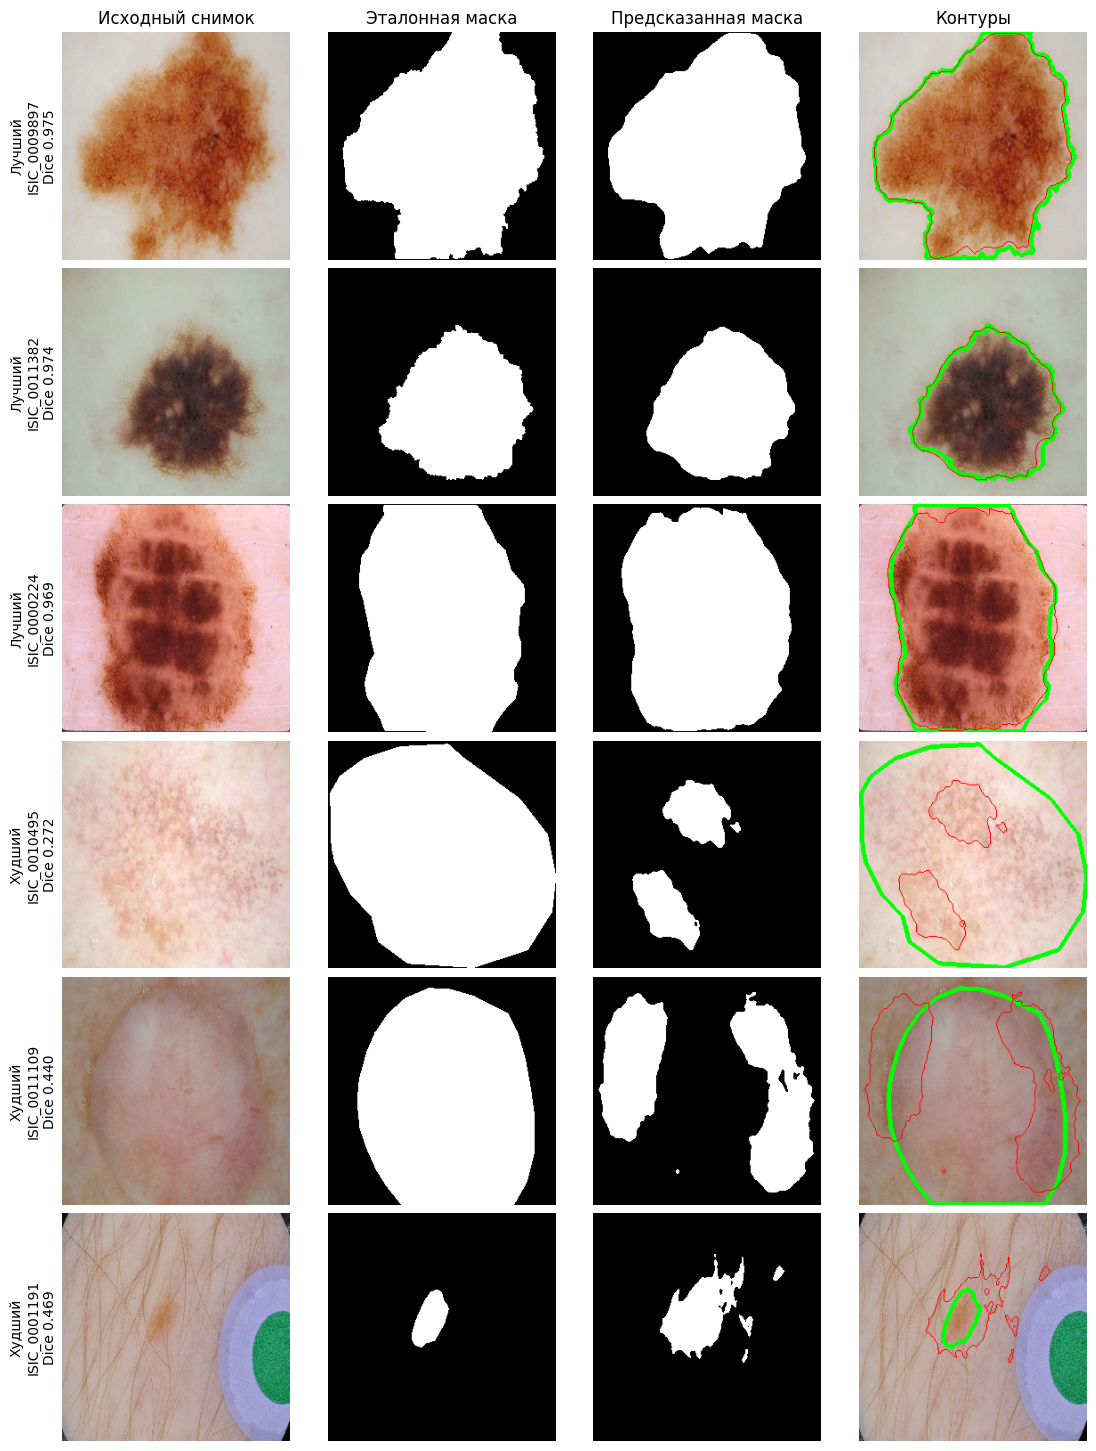

In [9]:
ranked_results = sorted(test_results, key=lambda row: (row["dice"], row["image_path"].stem))
worst_results = ranked_results[:3]
best_results = sorted(ranked_results[3:], key=lambda row: (-row["dice"], row["image_path"].stem))[:3]
selected = best_results + worst_results

figure, axes = plt.subplots(len(selected), 4, figsize=(11, 2.4 * len(selected)), layout="constrained")
for index, row in enumerate(selected):
    prediction, target = row["prediction"], row["target"]
    image_path = row["image_path"]
    with Image.open(image_path) as image_file:
        image = cv2.resize(
            np.asarray(image_file.convert("RGB")), (image_size, image_size),
            interpolation=cv2.INTER_LINEAR,
        )

    overlay = image.copy()
    for mask, color, width in ((target, (0, 255, 0), 3), (prediction, (255, 0, 0), 1)):
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, contours, -1, color, width)

    axes[index, 0].imshow(image)
    axes[index, 1].imshow(target, cmap="gray", vmin=0, vmax=1)
    axes[index, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[index, 3].imshow(overlay)
    for axis in axes[index]:
        axis.set_xticks([])
        axis.set_yticks([])
        for spine in axis.spines.values():
            spine.set_visible(False)

    rank = "Лучший" if index < len(best_results) else "Худший"
    axes[index, 0].set_ylabel(f"{rank}\n{image_path.stem}\nDice {row['dice']:.3f}")
    if index < len(best_results):
        continue

    missed = target & ~prediction
    extra = prediction & ~target
    disagreement = missed | extra
    grayscale = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    dark_details = cv2.morphologyEx(grayscale, cv2.MORPH_BLACKHAT, np.ones((9, 9), dtype=np.uint8))
    near_white = image.min(axis=2) >= 245

    observations = []
    if row["size_group"] == 0:
        observations.append("мелкий очаг, поэтому ошибка занимает значительную часть его площади")
    if disagreement.any() and (dark_details[disagreement] >= 25).mean() >= 0.02:
        observations.append("в зоне ошибки есть тёмные детали, возможен волосяной покров")
    if disagreement.any() and near_white[disagreement].mean() >= 0.005:
        observations.append("в зоне ошибки есть яркие участки, возможны блики")
    missed_boundary = inner_boundary(target) & missed
    if missed_boundary.any():
        gradient_x = cv2.Sobel(grayscale, cv2.CV_32F, 1, 0, ksize=3)
        gradient_y = cv2.Sobel(grayscale, cv2.CV_32F, 0, 1, ksize=3)
        gradient = cv2.magnitude(gradient_x, gradient_y)
        if np.median(gradient[missed_boundary]) < 20:
            observations.append("у пропущенного участка границы низкий контраст")

    missed_fraction = missed.sum() / max(target.sum(), 1)
    extra_fraction = extra.sum() / max((~target).sum(), 1)
    print(
        f"{image_path.stem} · Dice {row['dice']:.3f} · очаг {row['area']:.1%}. "
        f"Пропущено {missed_fraction:.1%} очага. В маску добавлено {extra_fraction:.1%} фона."
    )
    if observations:
        print("Возможные факторы ошибки — " + ", ".join(observations) + ".")
    else:
        print("Причина расхождения по измеренным признакам не определена.")

for axis, title in zip(axes[0], ("Исходный снимок", "Эталонная маска", "Предсказанная маска", "Контуры")):
    axis.set_title(title)
os.makedirs("assets", exist_ok=True)
plt.savefig("assets/demo_and_errors.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(figure)


# 10. Выводы и ограничения

- На данных ISIC 2016 Task 1 мы измерили среднюю долю фона 72,9%. В комбинированной функции потерь Dice учитывает перекрытие масок на каждом снимке, а Focal Loss уменьшает вклад уверенно классифицированных пикселей, включая большую часть простого фона. Чтобы измерить вклад Focal Loss, потребуется отдельный контрольный прогон с одним Dice Loss.
- При одинаковой ошибке в пикселях смещение границы сильнее снижает Dice у мелкого очага. При уменьшении снимка до 256 × 256 тонкие детали границы также могут исчезать. Разбивка в разделе 8 показывает, как качество меняется с размером очага.
- Волосы могут перекрывать границу, блики скрывают текстуру, а слабый контраст осложняет определение контура. В разделе 9 мы сопоставляем эти визуальные признаки с местами расхождения масок. Такой разбор даёт гипотезы о причинах ошибок.
- Мы можем проверить разрешение 512 × 512 для сохранения деталей контура и TTA с отражениями для усреднения карт вероятностей. Порог для каждого варианта следует подбирать на валидации, сохраняя одинаковые разбиения для сравнения.

**Модель выделяет область интереса для специалиста, но маска сама по себе не является диагнозом.**
